<a href="https://colab.research.google.com/github/uiwoos2/26-2-DIP-202202515/blob/main/HW/HW08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!pip install nibabel

In [15]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as nd
import scipy.signal as signal


In [16]:
h = nib.load('s02.nii.gz')
mri = h.get_fdata()
print(mri.shape)

(256, 256, 32)


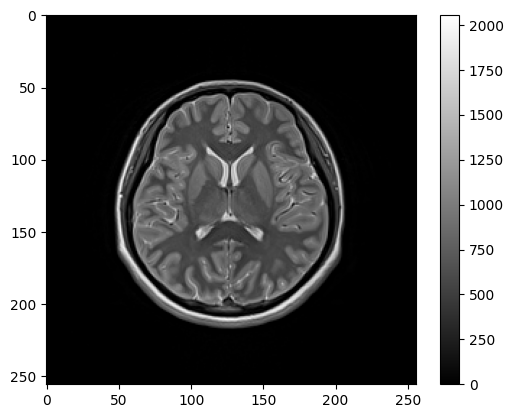

In [17]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

## Exerceise 1: Automatic Basic Global Thresholding
- 강의노트의 내용을 기반으로 하여 자동으로 global thresholding을 수행하는 영상처리코드를 작성하고, 적용한 결과를 확인하자.

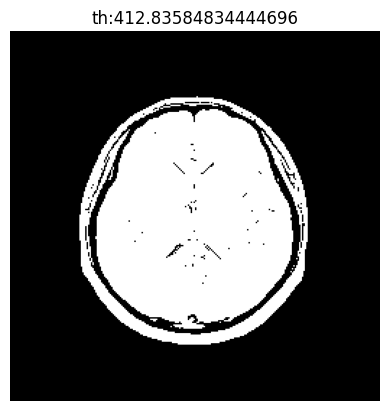

In [18]:
T_init = 1
T = []
T.append(T_init)
dT = 1000
esp = 5

## write down your algorithm
img = f
while dT > esp:
  G1 = f[f > T[-1]]
  G2 = f[f <= T[-1]]

  m1 = np.mean(G1) if G1.size > 0 else 0.0
  m2 = np.mean(G2) if G2.size > 0 else 0.0

  T_new = 0.5 * (m1 + m2)
  dT = np.abs(T_new - T[-1])
  T.append(T_new)
##

bmsk = img>T[-1]
plt.imshow(bmsk,cmap='gray')
plt.axis('off')
plt.title(f'th:{T[-1]}')
plt.show()

## Exercise 2: K-means clustering
- 강의노트의 "standard" k-means clustering algorithm을 완성하여 s02.nii.gz 파일에 적용해보자.
- k=2,3,4 일 때의 결과를 s02.nii.gz에 대해 각각 비교해보자.

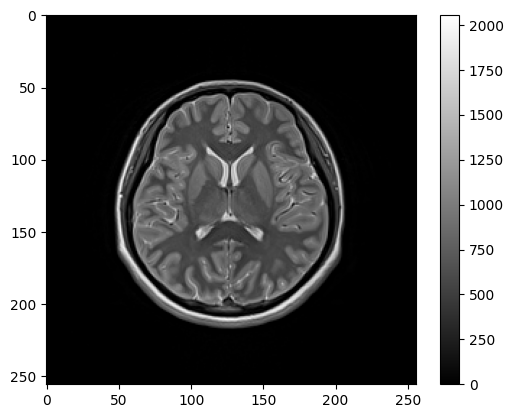

In [ ]:
f = mri[::-1,::-1,18].transpose((1,0))
plt.imshow(f,cmap='gray')
plt.colorbar()
plt.show()

### k = 2 에서의 결과

[ 64. 128.]
[  5.91248043 768.93253625]
[ 13.3779618  806.97810069]
[ 14.87874927 810.79294742]


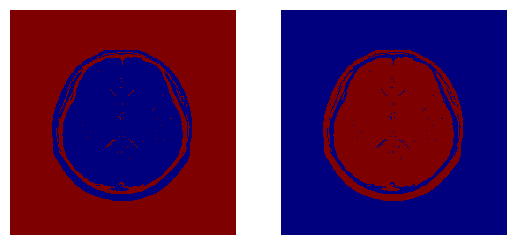

In [19]:
m_vals = np.array([64., 128.])
c = np.zeros((f.shape[0],f.shape[1],len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E=10000
eps = 1
cmap = np.argmin(c,axis=-1)
while E>eps:
  print(m_vals)
  ##

  # your k-means clustering algorithm #
  for i in range(len(m_vals)):
        c[:, :, i] = (f - m_vals[i]) ** 2
  cmap = np.argmin(c, axis=-1)

  for i in range(len(m_vals)):
    if np.any(cmap == i):
      m_vals_new[i] = np.mean(f[cmap == i])
    else:
      m_vals_new[i] = 0.0

    E = np.linalg.norm(m_vals_new - m_vals)
    m_vals = m_vals_new.copy()

    ##


for i in range(len(m_vals)):
  plt.subplot(1,len(m_vals),i+1)
  plt.imshow(cmap==i,cmap='jet',interpolation='nearest')
  plt.axis('off')
plt.show()

### k = 3 에서의 결과

[  0.  64. 128.]
[  5.09165359  53.9587217  768.93253625]
[  4.99728304 188.19603175 811.00098871]
[  5.91248043 351.70671378 834.54428762]
[  6.98596017 486.54207842 910.73659707]
[  8.32999868 545.23248696 978.65010589]
[   9.12865176  574.60940919 1012.99939735]
[   9.54000526  592.66307253 1035.3296667 ]
[   9.85371571  605.24011918 1051.99599104]
[  10.05355227  614.64670154 1065.68227801]
[  10.21120812  622.74926519 1078.41098959]
[  10.37108239  629.26078993 1089.13604411]
[  10.52586018  635.67448908 1100.43707557]
[  10.68196814  641.55576675 1111.4076202 ]
[  10.77806173  646.58305995 1121.70193976]
[  10.84722556  651.33894336 1132.17228896]
[  10.95876356  655.94834161 1142.60466712]
[  11.02891813  660.47762144 1153.86921421]
[  11.11352578  664.80899033 1165.13348331]
[  11.19872172  668.44071988 1174.99376826]
[  11.26299834  672.37427217 1186.55616606]
[  11.35628475  676.21607537 1198.2045068 ]
[  11.4789024   680.52404163 1211.92866726]
[  11.60978214  684.70800026 1

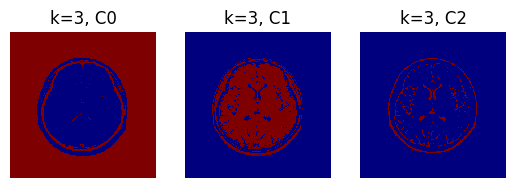

In [23]:
m_vals = np.array([0., 64., 128.])
c = np.zeros((f.shape[0], f.shape[1], len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E = 10000
eps = 1
cmap = np.argmin(c, axis=-1)

while E > eps:
    print(m_vals)
    for i in range(len(m_vals)):
        c[:, :, i] = (f - m_vals[i]) ** 2
    cmap = np.argmin(c, axis=-1)

    for i in range(len(m_vals)):
        if np.any(cmap == i):
            m_vals_new[i] = np.mean(f[cmap == i])
        else:
            m_vals_new[i] = 0.0

    E = np.linalg.norm(m_vals_new - m_vals)
    m_vals = m_vals_new.copy()

for i in range(len(m_vals)):
    plt.subplot(1, len(m_vals), i + 1)
    plt.imshow(cmap == i, cmap='jet', interpolation='nearest')
    plt.title(f'k=3, C{i}')
    plt.axis('off')
plt.show()

### k = 4 에서의 결과

[  0.  64. 128. 192.]
[  5.09165359  53.9587217  127.4        778.62619419]
[  4.99728304  48.18835616 297.86718371 819.37158208]
[  4.88759148  67.14854828 451.9274441  874.35171677]
[  5.19810059 124.63636364 534.58792585 959.73888613]
[   5.54670713  192.35397554  576.57465443 1005.31780528]
[   5.94110545  247.93926247  603.54505516 1032.8123231 ]
[   6.27007267  291.72901986  625.5378844  1056.64927257]
[   6.58786774  332.33096668  645.80638241 1079.73221147]
[   6.88948069  371.53016859  666.52628346 1103.73516918]
[   7.19355768  412.11561866  691.86206897 1133.6041046 ]
[   7.52500166  453.03321123  725.11706655 1172.77254296]
[   7.94274489  493.89392133  773.28436392 1229.27088788]
[   8.43043105  521.270174    819.21002188 1305.85047884]
[   8.81819581  537.76316114  851.64943014 1390.84699233]
[   9.02933486  547.68757273  871.11668449 1447.64858377]
[   9.18168442  554.22606742  883.07734028 1480.52391073]
[   9.22337622  557.74011673  889.73007008 1498.1650758 ]
[   9.27

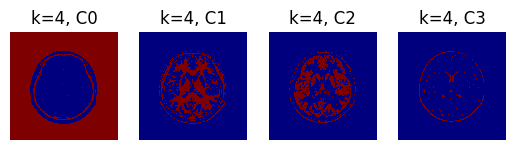

In [21]:
m_vals = np.array([0., 64., 128., 192.])
c = np.zeros((f.shape[0], f.shape[1], len(m_vals)))
cmap = np.zeros_like(f)
m_vals_new = np.zeros(m_vals.shape)
E = 10000
eps = 1
cmap = np.argmin(c, axis=-1)

while E > eps:
    print(m_vals)
    for i in range(len(m_vals)):
        c[:, :, i] = (f - m_vals[i]) ** 2
    cmap = np.argmin(c, axis=-1)

    for i in range(len(m_vals)):
        if np.any(cmap == i):
            m_vals_new[i] = np.mean(f[cmap == i])
        else:
            m_vals_new[i] = 0.0

    E = np.linalg.norm(m_vals_new - m_vals)
    m_vals = m_vals_new.copy()

for i in range(len(m_vals)):
    plt.subplot(1, len(m_vals), i + 1)
    plt.imshow(cmap == i, cmap='jet', interpolation='nearest')
    plt.title(f'k=4, C{i}')
    plt.axis('off')
plt.show()